In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [76]:
df = pd.read_csv("wdbc.data", sep=",")
columns=['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']
df.columns=columns

In [77]:
df.sample(5)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
474,911408,B,12.83,15.73,82.89,506.9,0.09040,0.08269,0.05835,0.030780,...,14.09,19.35,93.22,605.8,0.1326,0.26100,0.34760,0.09783,0.3006,0.07802
84,8612399,M,18.46,18.52,121.10,1075.0,0.09874,0.10530,0.13350,0.087950,...,22.93,27.68,152.20,1603.0,0.1398,0.20890,0.31570,0.16420,0.3695,0.08579
424,907367,B,10.03,21.28,63.19,307.3,0.08117,0.03912,0.00247,0.005159,...,11.11,28.94,69.92,376.3,0.1126,0.07094,0.01235,0.02579,0.2349,0.08061
529,91858,B,11.75,17.56,75.89,422.9,0.10730,0.09713,0.05282,0.044400,...,13.50,27.98,88.52,552.3,0.1349,0.18540,0.13660,0.10100,0.2478,0.07757
121,865423,M,24.25,20.20,166.20,1761.0,0.14470,0.28670,0.42680,0.201200,...,26.02,23.99,180.90,2073.0,0.1696,0.42440,0.58030,0.22480,0.3222,0.08009


In [78]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()

In [79]:
df['class'] = df['diagnosis'].map({'M':1, 'B':0})
df.drop(['id', 'diagnosis'], axis=1, inplace=True)

In [80]:
sc.fit_transform(df)

array([[ 1.83208378, -0.35832707,  1.68910604, ..., -0.24044363,
         0.28529387,  1.30074714],
       [ 1.58210603,  0.45385958,  1.56958968, ...,  1.16385786,
         0.2053006 ,  1.30074714],
       [-0.76711673,  0.25081292, -0.59077158, ...,  6.08623563,
         4.95045676,  1.30074714],
       ...,
       [ 0.70434323,  2.04789258,  0.6752776 , ..., -1.10613122,
        -0.31576665,  1.30074714],
       [ 1.84060575,  2.33962629,  1.98583632, ...,  1.93516598,
         2.22846365,  1.30074714],
       [-1.80679694,  1.22170271, -1.81313547, ..., -0.04354852,
        -0.74961903, -0.76878893]], shape=(568, 31))

In [81]:
df.to_csv("without_pca.csv",index=False)

NOW I WILL START PCA TO REDUCE NUMBER OF COLUMNS FROM 30 TO ANYTHING LOWER

In [82]:
y=df['class']
df.drop(['class'], axis=1, inplace=True)

<Axes: >

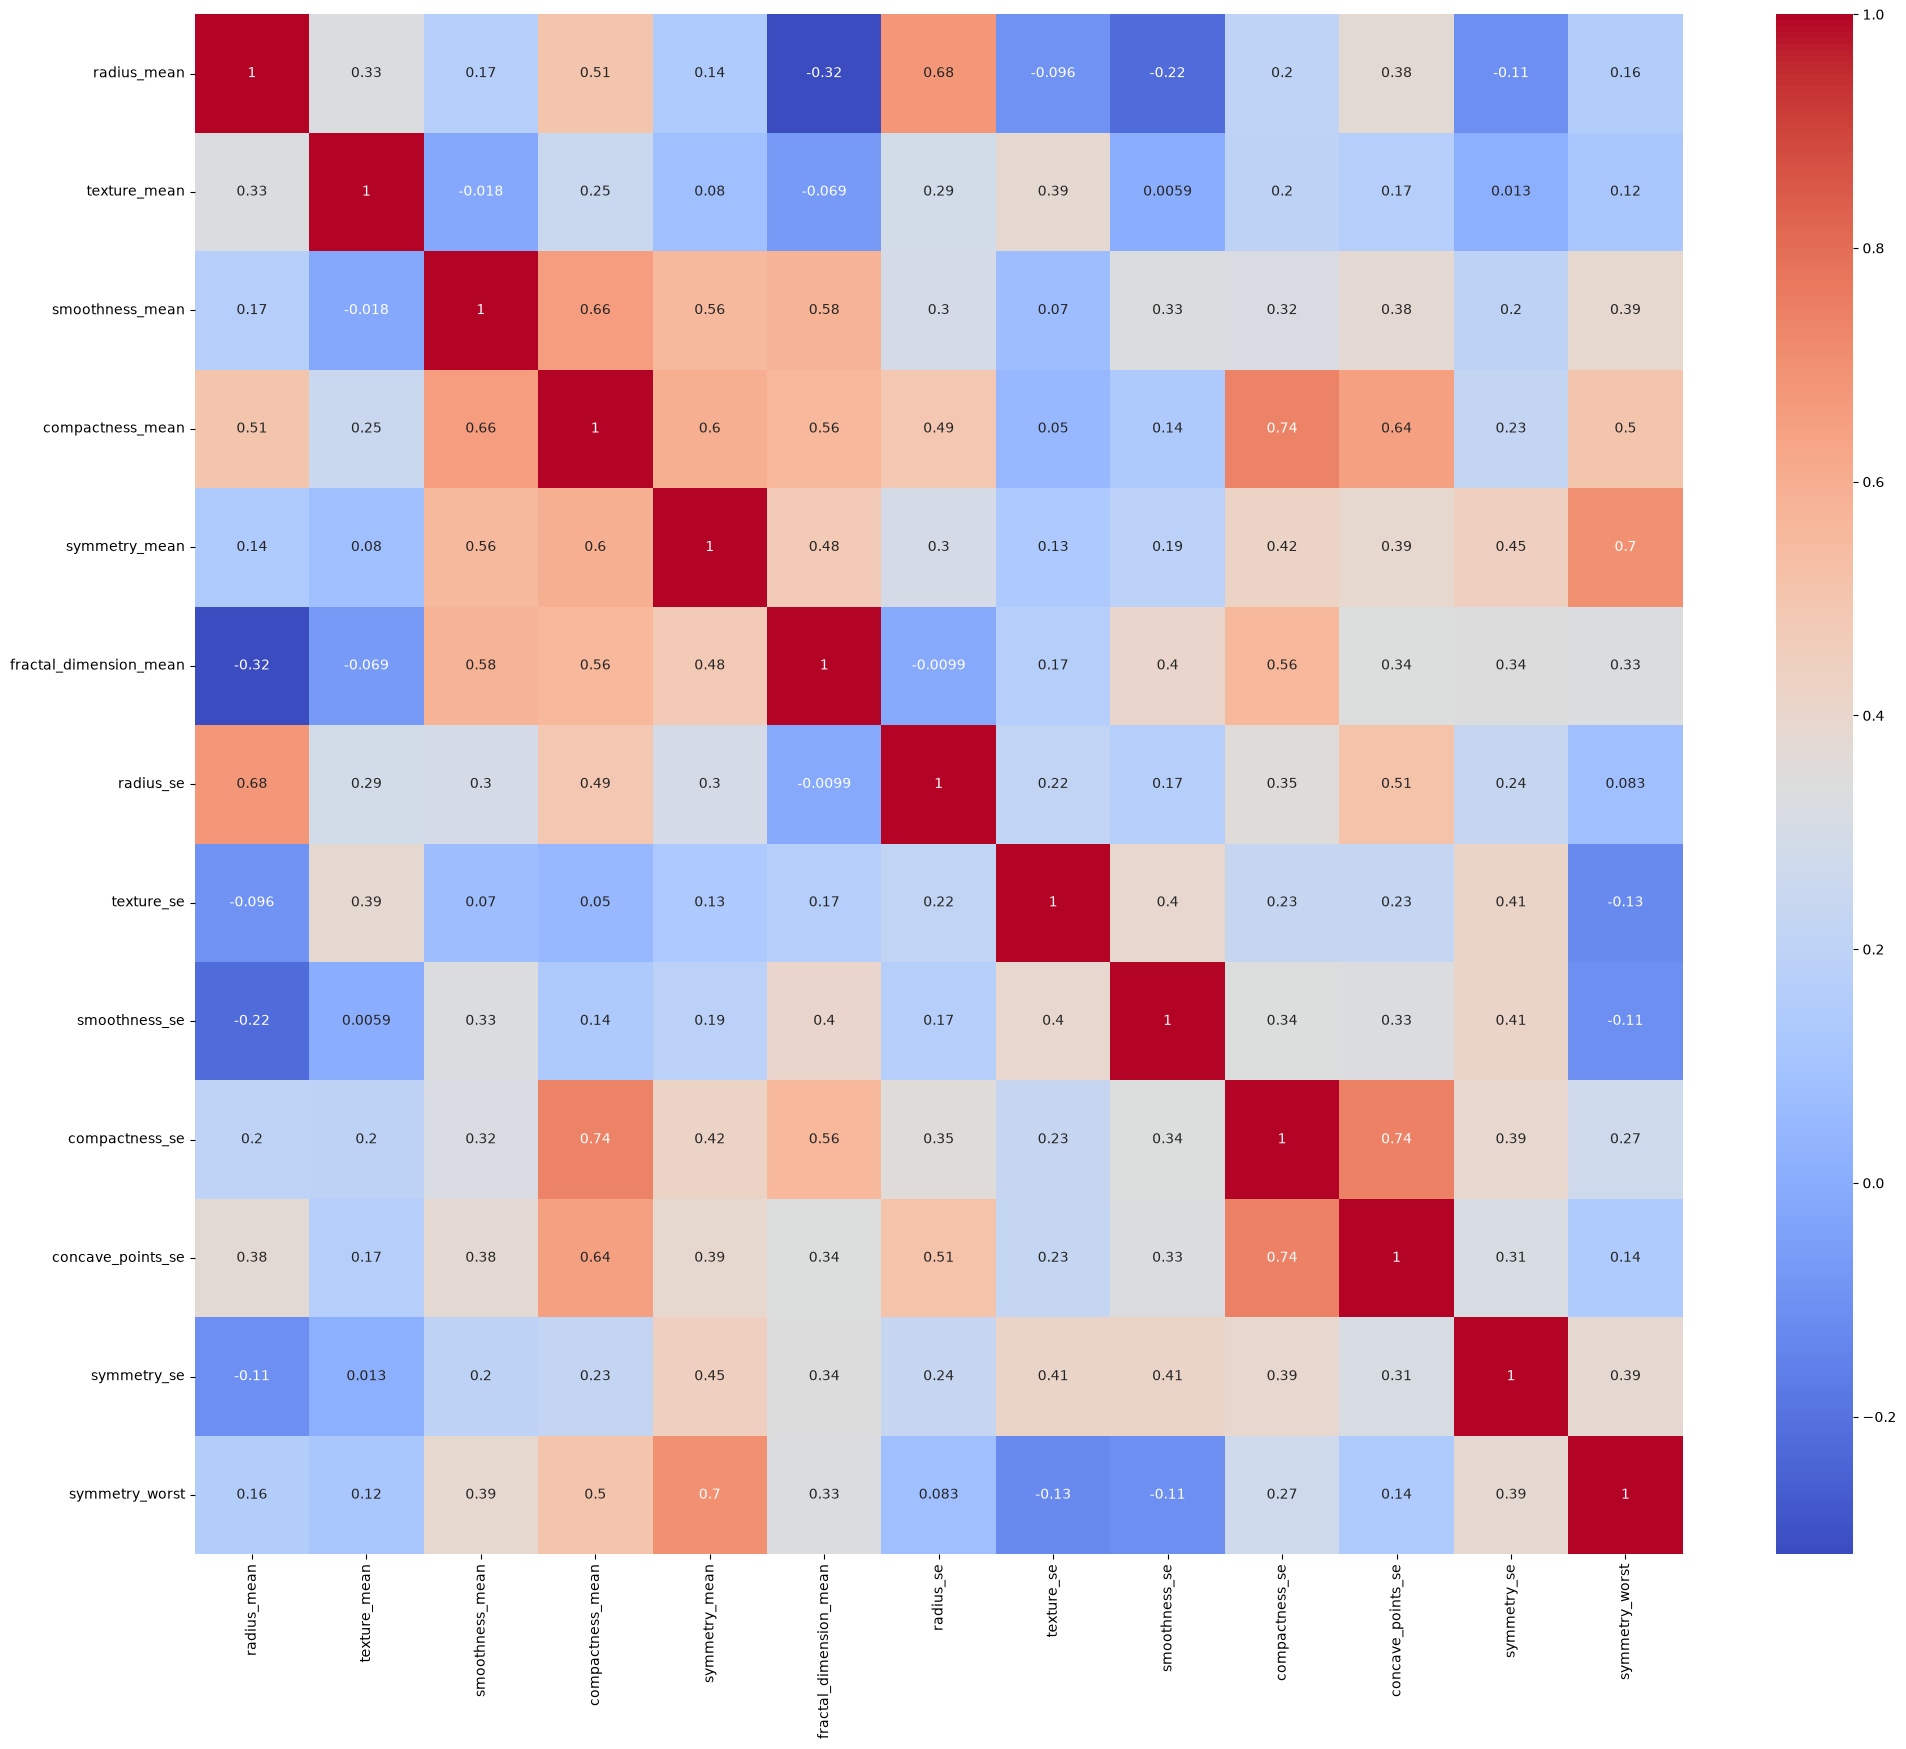

In [86]:
plt.figure(figsize=(24,20))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

POINTS TO BE NOTED FROM THE CORRELATION HEATMAP
1.PERIMETER_MEAN, AREA_ME AND RADIUS_MEAN ARE COMPLETELY SAME FEATURES SO TWO CAN BE DROPPED
2.PERIMETER_SE, AREA_SE AND RADIUS_SE ARE COMPLETELY SAME FEATURES SO TWO CAN BE DROPPED
3.THE COLUMNS IN THE ABOVE 2 POINTS WILL ALSO BE HIGHLY CORELATED SO CAN BE TRANSFROMED INTO ONE
4.PERIMETER_WORST, AREA_WORST AND RADIUS_WORST ARE COMPLETELY SAME FEATURES SO TWO CAN BE DROPPED
5.CONCAVITY WORST AND MEAN ARE ALSO SAME
6.CONCAVITY MEAN, CONCAVE_POINTS WORST AND RADIUS MEAN WILL BE COMBINED TO FORM ONE COLUMN
THAT'S IT FROM THE CURRENT CORRELATION TABLE

In [84]:
def drop_corr(df, threshold=0.80):
    corr_matrix = df.corr().abs()
    upper = corr_matrix.where(pd.DataFrame([[i < j for j in range(len(corr_matrix.columns))]for i in range(len(corr_matrix.columns))],
            index=corr_matrix.columns,
            columns=corr_matrix.columns
        )
    )
    to_drop = [col for col in upper.columns if (upper[col] >= threshold).any()]
    return df.drop(columns=to_drop)

In [85]:
df=drop_corr(df,0.80)

In [70]:
from sklearn.decomposition import PCA
p=PCA(n_components=2,svd_solver='covariance_eigh', random_state=42)

In [71]:
df_pca=p.fit_transform(df)

In [72]:
df_pca = pd.DataFrame(df_pca, columns=['PC1', 'PC2'])
df_pca['class'] = y.values

In [73]:
df_pca["class"].value_counts()

class
0    357
1    211
Name: count, dtype: int64

In [74]:
df_pca.to_csv("with_pca.csv",index=False)